# Prot2GO Protein Dataset EDA
Author: Cleverson M., PhD

**Database of Interacting Proteins (DIP)**

Protein–protein interactions in DIP are manually curated from articles in peer-reviewed journals.

Xenarios, I. (2000) ‘DIP: the Database of Interacting Proteins’, Nucleic Acids Research, 28(1), pp. 289–291. Available at: https://doi.org/10.1093/nar/28.1.289.

## Environment

In [58]:
# Imports

import os
import re
from pathlib import Path
import warnings
import numpy as np
import pandas as pd
import IPython
from tqdm.auto import tqdm
import requests
import pickle
import subprocess
import json
from itertools import product

import matplotlib.pyplot as plt
import seaborn as sns
import plotly.express as px

from Bio import SeqIO
import networkx as nx

import torch
from torch.utils.data import DataLoader, Dataset
from torch_geometric.data import Data
from transformers import BertTokenizer, BertModel
from bertviz import head_view
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.cluster import KMeans
from yellowbrick.cluster import KElbowVisualizer
from sklearn.metrics import silhouette_score
from sklearn.manifold import SpectralEmbedding

from sklearn.decomposition import PCA
import hdbscan
import umap


# disable warnings
warnings.filterwarnings("ignore")

# folder paths
root = Path("/home/clever/datascience/projects/prot2go")

In [2]:
# Protein and Embeddings Datasets Classes


class ProteinSequenceDataset(Dataset):
    """
    A PyTorch Dataset class for reading and preprocessing protein sequences for embedding generation.

    Attributes:
        dataframe (pd.DataFrame): A dataframe with UniProt IDs, protein sequences (1-letter a. a. code)
        and their sequence lengths (column names: "uniprot_id", "sequence", "lenght").

    Methods:
        __len__: Returns the number of files in the dataset.
        __getitem__: Retrieves a sequence and its identifier by index, applying preprocessing.
    """

    def __init__(self, dataframe):
        """
        Initializes the ProteinSequenceDataset with a dataframe.

        Parameters:
            dataframe (pd.DataFrame): A dataframe with UniProt IDs, protein sequences (1-letter a. a. code)
        and their sequence lengths (column names: "uniprot_id", "sequence", "lenght").
        """
        self.dataframe = dataframe

    def __len__(self):
        """
        Provides the size of the dataset.

        Returns:
            int: The number of sequences in the dataframe.
        """
        return len(self.dataframe)

    def __getitem__(self, idx):
        """
        Retrieves the sequence and its identifier at the specified index after preprocessing.

        Parameters:
            idx (int): The index of the sequence to retrieve.

        Returns:
            tuple: A tuple containing the preprocessed sequence and its id.
        """
        row = self.dataframe.iloc[idx]
        seq = " ".join(row["sequence"].replace(r"[UZOB]", "X"))

        return seq, row["uniprot_id"]


class EmbDataset(Dataset):
    """
    A PyTorch Dataset for loading protein embeddings stored as .pt (PyTorch tensor) files.

    Each tensor file contains the embedding of a protein, identified by a UniProt ID. This dataset
    facilitates the access to these embeddings for model training or inference, ensuring each
    embedding is loaded as needed, thus optimizing memory usage.

    Attributes:
        tensor_folder (str): The directory path where the embedding tensors (.pt files) are stored.
        uniprot_ids (list): A list of UniProt IDs corresponding to the proteins for which embeddings are available.

    Methods:
        __len__: Returns the total number of embeddings available in the dataset.
        __getitem__: Retrieves an embedding by its index, along with its corresponding UniProt ID.

    Parameters:
        tensor_folder (str): Path to the folder where tensor files, representing protein embeddings, are stored.
                             Each file should be named with the UniProt ID of the protein it represents.
    """

    def __init__(self, tensor_folder):
        """
        Initializes the dataset with the path to the directory containing the embeddings.

        Args:
            tensor_folder (string): Path to the folder where tensors are stored.
        """
        self.tensor_folder = tensor_folder
        self.uniprot_ids = [
            file.split(".")[0]
            for file in os.listdir(tensor_folder)
            if file.endswith(".pt")
        ]

    def __len__(self):
        """
        Returns the total number of protein embeddings available.

        Returns:
            int: The count of UniProt ID-based tensor files in the tensor folder.
        """
        return len(self.uniprot_ids)

    def __getitem__(self, idx):
        """
        Retrieves a specific protein embedding and its corresponding UniProt ID by index.

        This method ensures that the embedding tensor is loaded from disk only when accessed,
        optimizing memory usage, especially useful when dealing with large datasets.

        Args:
            idx (int): The index of the protein embedding to retrieve.

        Returns:
            dict: A dictionary containing the UniProt ID ('uniprot_id') and the embedding tensor ('tensor').
                  The tensor is expected to have a shape of (1, 1024).

        Raises:
            AssertionError: If the loaded tensor does not match the expected shape of (1, 1024).
        """
        uniprot_id = self.uniprot_ids[idx]
        tensor_path = os.path.join(self.tensor_folder, uniprot_id + ".pt")
        tensor = torch.load(tensor_path)

        # Asserting the tensor is in the correct shape ensures consistency and prevents potential errors in downstream processes.
        assert tensor.shape == (
            1,
            1024,
        ), f"Tensor shape mismatch: {tensor.shape} != (1, 1024)"

        return {"uniprot_id": uniprot_id, "tensor": tensor}

In [3]:
# Helper functions


def embed_sequences(
    dataframe: pd.DataFrame, out_dir: Path, per_residue=False, batch_size=1
):
    """
    Processes protein sequences from a folder, generating embeddings using a pre-trained BERT model.

    Parameters:
        dataframe (pd.DataFrame): A dataframe with protein IDs, corresponding peptide sequences and their lengths.
        per_residue (bool): If True, saves per-residue embeddings; otherwise, saves per-protein embeddings.
        batch_size (int): The batch size for processing sequences.
    """

    print(f"Loading transformer and tokenizer...")
    tokenizer = BertTokenizer.from_pretrained("Rostlab/prot_bert", do_lower_case=False)
    model = BertModel.from_pretrained("Rostlab/prot_bert")
    device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
    model.to(device).half().eval()  # move model to gpu and set half-precision (float16)

    # Creates directories to save embeddings
    out_dir = Path(out_dir)  # ensures Path object
    out_dir.mkdir(parents=True, exist_ok=True)

    per_protein_path = out_dir / "per_protein"
    per_protein_path.mkdir(exist_ok=True, parents=True)

    per_residue_path = out_dir / "per_residue" if per_residue else None
    if per_residue_path:
        per_residue_path.mkdir(exist_ok=True, parents=True)

    # Reads fasta files in input folder
    dataset = ProteinSequenceDataset(dataframe)
    loader = DataLoader(dataset, batch_size=batch_size, shuffle=False)

    for seqs, ids in tqdm(loader, desc="Embedding sequences"):
        for seq, seq_id in zip(seqs, ids):

            # Tokenize and move input tensors to the same device as the model
            inputs = tokenizer(seq, padding=True, truncation=True, return_tensors="pt")
            inputs = {key: tensor.to(device) for key, tensor in inputs.items()}

            with torch.no_grad():
                outputs = model(**inputs)
            protein_embeddings = outputs.last_hidden_state[
                :, : len(seq.replace(" ", "")) + 1
            ]

            # Detach and move to CPU before saving
            protein_embeddings = protein_embeddings.mean(dim=1).detach().cpu()
            torch.save(protein_embeddings, per_protein_path / f"{seq_id}.pt")

            if per_residue:
                residue_embeddings = outputs.last_hidden_state[
                    :, : len(seq.replace(" ", "")) + 1
                ]
                torch.save(
                    residue_embeddings.detach().cpu(),
                    per_residue_path / f"{seq_id}_res_embed.pt",
                )

    print(f"All proteins embedded successfully.")


def call_html():
    """
    Embeds necessary JavaScript and HTML for visualizing BERT attentions using bertviz library in a Jupyter notebook.

    This function loads JavaScript libraries like d3 and jQuery using require.js. These libraries are essential
    for bertviz visualizations. It must be called in a Jupyter notebook before using bertviz visualizations.
    """
    display(
        IPython.core.display.HTML(
            """
            <script src="/static/components/requirejs/require.js"></script>
            <script>
              requirejs.config({
                paths: {
                  base: '/static/base',
                  "d3": "https://cdnjs.cloudflare.com/ajax/libs/d3/3.5.8/d3.min",
                  jquery: '//ajax.googleapis.com/ajax/libs/jquery/2.0.0/jquery.min',
                },
              });
            </script>
            """
        )
    )


def show_head_view(model, tokenizer, sequence):
    """
    Visualizes the attention heads of a BERT model for a given sequence.

    Args:
    - model (BertModel): The pre-trained BERT model.
    - tokenizer (BertTokenizer): The tokenizer corresponding to the BERT model.
    - sequence (str): The input sequence to visualize attentions for.

    This function processes the input sequence with the given tokenizer, passes it through the BERT model,
    and visualizes the attention heads. It requires the bertviz library for visualization. The model is set to
    evaluation mode and moved to the appropriate device (CPU/GPU) before inference.
    """

    # ensure the model is in evaluation mode and on the right device
    device = "cuda" if torch.cuda.is_available() else "cpu"
    model = model.to(device)
    model.eval()

    # tokenize the input sequence and convert to tensor
    inputs = tokenizer.encode_plus(
        sequence, return_tensors="pt", add_special_tokens=True
    )
    input_ids = inputs["input_ids"].to(device)

    # obtain the model's attention weights
    with torch.no_grad():
        attention = model(input_ids)[-1]

    # convert input ids to tokens
    input_id_list = input_ids[0].tolist()  # Retrieve the first batch
    tokens = tokenizer.convert_ids_to_tokens(input_id_list)

    # visualize the attention heads (head_view function from bertviz)
    head_view(attention, tokens)


def plot_graph_centrality(
    G: nx.Graph,
    centrality_type: str = "degree",
    num_top_nodes: int = 100,
    iterations: int = 100,
    figure_size: tuple = (16, 16),
    plot_labels: bool = True,
    node_color_scale: bool = True,
    node_alpha: float = 0.5,
    edge_alpha: float = 0.4,
    cmap: plt.cm = plt.cm.viridis,
    fixed_node_size: int = 300,
    font_color: str = "black",
    font_size: int = 10,
    font_alpha: float = 0.3,
):
    """
    Plots a graph focusing on the top nodes according to selected centrality measures, visually emphasizing
    the importance of nodes in a network based on the specified centrality measure. This function supports various
    centrality metrics and visual customization options.

    Args:
        G (nx.Graph): The graph to plot.
        centrality_type (str): Type of centrality measure ('degree', 'eigenvector', 'betweenness', 'closeness', 'clustering').
        num_top_nodes (int, optional): Number of top nodes to plot based on the centrality measure.
        iterations (int, optional): Number of iterations for the layout algorithm.
        figure_size (tuple, optional): Dimensions of the figure (width, height).
        plot_labels (bool, optional): Flag to determine whether labels should be displayed for nodes.
        node_color_scale (bool, optional): Whether to scale node colors by the selected centrality measure.
        node_alpha (float, optional): Transparency level of nodes.
        edge_alpha (float, optional): Transparency level of edges.
        cmap (Colormap, optional): Colormap for node colors if scaled.
        fixed_node_size (int, optional): Fixed size for all nodes if not scaling by centrality measure.
        font_color (str, optional): Color of the font for node labels.
        font_size (int, optional): Font size for node labels.
        font_alpha (float, optional): Transparency level of font labels.

    Raises:
        ValueError: If an invalid centrality measure is specified.
    Returns:
        A python dictionary with node ids as keys and centrality as values in descending order of centrality.

    Example usage:
        G = nx.gnp_random_graph(100, 0.05)
        plot_graph_centrality(
            G, centrality_type="closeness", num_top_nodes=10, node_color_scale=True
        )
    """

    # Select and compute the appropriate centrality measure based on input
    centrality_methods = {
        "degree": lambda G: dict(G.degree()),
        "eigenvector": nx.eigenvector_centrality,
        "betweenness": nx.betweenness_centrality,
        "closeness": nx.closeness_centrality,
        "clustering": nx.clustering,
    }

    if centrality_type not in centrality_methods:
        raise ValueError(f"Invalid centrality measure specified: {centrality_type}")

    centrality = centrality_methods[centrality_type](G)

    # Sort nodes by selected centrality and select the top nodes
    top_nodes = sorted(centrality.items(), key=lambda x: x[1], reverse=True)[
        :num_top_nodes
    ]
    subgraph = G.subgraph([node for node, _ in top_nodes])

    # Set up color and size mappings based on centrality
    if node_color_scale:
        node_color = [centrality[node] for node in subgraph.nodes()]
        node_size = [
            centrality[node] * 1000 if centrality_type != "degree" else centrality[node]
            for node in subgraph.nodes()
        ]
    else:
        node_color = "skyblue"
        node_size = [fixed_node_size] * len(subgraph)

    plt.figure(figsize=figure_size)
    pos = nx.spring_layout(subgraph, iterations=iterations)

    nx.draw_networkx_nodes(
        subgraph,
        pos,
        node_size=node_size,
        node_color=node_color,
        alpha=node_alpha,
        cmap=cmap,
    )
    nx.draw_networkx_edges(subgraph, pos, alpha=edge_alpha)

    if plot_labels:
        labels = {node: f"{node}\n{centrality[node]:.2f}" for node in subgraph.nodes()}
        nx.draw_networkx_labels(
            subgraph,
            pos,
            labels=labels,
            font_color=font_color,
            font_size=font_size,
            alpha=font_alpha,
        )

    plt.title(f"Graph with top {num_top_nodes} nodes by {centrality_type} centrality")
    plt.axis("off")
    plt.show()

    return dict(top_nodes)


def plot_centrality_histogram(G: nx.Graph, centrality_type="degree", bins=15):
    """
    Plots a histogram for a specified centrality measure of a graph.

    Parameters:
    - G (nx.Graph): The graph from which to plot centrality distribution.
    - centrality_type (str): The type of centrality measure to plot ('degree', 'eigenvector', 'betweenness', 'closeness', 'clustering').
    - bins (int): Number of bins to use in the histogram.

    Returns:
        A python dictionary with node ids as keys and centrality as values in descending order of centrality.

    """
    if centrality_type == "degree":
        centrality = dict(G.degree())
        title = "Degree Centrality Distribution"
    elif centrality_type == "eigenvector":
        centrality = nx.eigenvector_centrality(G)
        title = "Eigenvector Centrality Distribution"
    elif centrality_type == "betweenness":
        centrality = nx.betweenness_centrality(G)
        title = "Betweenness Centrality Distribution"
    elif centrality_type == "closeness":
        centrality = nx.closeness_centrality(G)
        title = "Closeness Centrality Distribution"
    elif centrality_type == "clustering":
        centrality = nx.clustering(G)
        title = "Clustering Coefficient Distribution"
    else:
        raise ValueError(
            "Invalid centrality measure. Choose 'degree', 'eigenvector', 'betweenness', 'closeness', or 'clustering'."
        )

    # Convert centrality values to a list
    centrality_values = list(centrality.values())

    # Set up the plot
    plt.figure(figsize=(8, 5))
    sns.histplot(centrality_values, bins=bins, color="skyblue", edgecolor="black")
    plt.title(title)
    plt.xlabel(centrality_type.capitalize() + " Centrality")
    plt.ylabel("Frequency")
    plt.show()

    return dict(sorted(centrality.items(), key=lambda x: x[1], reverse=True))


def annotate_proteins(ids_to_annotate, fetch_go=True):
    """
    Retrieves annotations selectively from UniProt and optionally Gene Ontology (GO) for a list of UniProt IDs.

    Parameters:
    - ids_to_annotate (list): List of UniProt IDs to retrieve annotations for.
    - fetch_go (bool): If True, fetches GO annotations.

    Returns:
    - tuple: A pandas DataFrame for UniProt annotations, and optionally another DataFrame for GO annotations.
    """
    uniprot_annotations = []
    go_annotations_list = []

    for protein_id in tqdm(ids_to_annotate, desc="Fetching Annotations"):
        # UniProt Full Annotations - Always fetched
        try:
            url = f"https://www.uniprot.org/uniprot/{protein_id}.txt"
            response = requests.get(url)
            if response.ok:
                uniprot_annotations.append(
                    {"UniProt_ID": protein_id, "UniProt_Annotation": response.text}
                )
        except Exception as e:
            print(
                f"UniProt full annotation retrieval failed for {protein_id}. Error: {str(e)}"
            )

        # GO Annotations - Fetched if requested

        # Define mapping for categorical aspects:
        aspect_mapping = {
            "C": "cellular_component",
            "F": "molecular_function",
            "P": "biological_process",
        }
        if fetch_go and response.ok:
            go_annotations = []
            try:
                data = response.text
                for line in data.splitlines():
                    if line.startswith("DR   GO;"):
                        go_info = line.split("; ")
                        go_id = "GO:" + go_info[1].split(":")[1]
                        aspect, go_term = go_info[2].rstrip(".").split(":")
                        go_annotations.append(
                            {
                                "uniprot_id": protein_id,
                                "go_id": go_id,
                                "name": go_term,
                                "aspect": aspect_mapping.get(aspect, aspect),
                            }
                        )
                go_annotations_list.extend(go_annotations)
            except Exception as e:
                print(
                    f"GO annotation retrieval failed for {protein_id}. Error: {str(e)}"
                )

    # Convert lists to DataFrames
    uniprot_df = pd.DataFrame(uniprot_annotations)
    if fetch_go:
        go_df = pd.DataFrame(go_annotations_list)
        return uniprot_df, go_df
    else:
        return (
            uniprot_df,
            pd.DataFrame(),
        )  # Return an empty DataFrame if GO was not fetched


def plot_tfidf(
    texts,
    max_df=0.85,
    min_df=2,
    n_gram_range=(1, 2),
    top_n=25,
):
    """
    Computes and visualizes the top N terms with the highest TF-IDF scores.

    Parameters:
    - texts (iterable): Iterable (list, np.array, pd.Series) containing the text data.
    - max_df (float): Maximum document frequency allowed for tokens.
    - min_df (int or float): Minimum document frequency required for tokens.
    - n_gram_range (tuple): The lower and upper boundary of the range of n-values for different n-grams.
    - top_n (int): Number of top terms to visualize.

    Returns:
    - None: Displays a bar chart of the top terms with their TF-IDF scores.
    """
    # Ensure input is in an appropriate format for vectorization
    if isinstance(texts, pd.Series):
        texts = texts.values  # Convert pd.Series to np.array
    elif isinstance(texts, list):
        texts = np.array(texts)  # Convert list to np.array

    # Initialize the TfidfVectorizer
    vectorizer = TfidfVectorizer(max_df=max_df, min_df=min_df, ngram_range=n_gram_range)

    # Generate the TF-IDF matrix
    tf_idf_matrix = vectorizer.fit_transform(texts)
    features = vectorizer.get_feature_names_out()

    # Compute the maximum TF-IDF score for each feature across all documents
    max_scores = np.max(tf_idf_matrix, axis=0).toarray().flatten()

    # Obtain sorted indices (descending order) and select the top N features
    sorted_indices = np.argsort(max_scores)[::-1][:top_n]
    sorted_features = features[sorted_indices]
    sorted_scores = max_scores[sorted_indices]

    # Create a bar chart
    plt.figure(figsize=(12, 8))
    bars = plt.barh(sorted_features, sorted_scores, color="green")
    plt.xlabel("Max TF-IDF Score")
    plt.title(f"Top {top_n} Terms with Highest TF-IDF Scores")
    plt.gca().invert_yaxis()  # Invert y-axis to have the highest score on top

    # Add data labels to each bar
    for bar in bars:
        plt.gca().text(
            bar.get_width(),
            bar.get_y() + bar.get_height() / 2,
            f"{bar.get_width():.2f}",
            ha="left",
            va="center",
            color="black",
        )

    # Show plot with interactive mode on
    plt.show()


def extract_uniprot_ids(field):
    if pd.isna(field):
        return None
    split_field = field.split("|")
    fragment_list = [
        uniprot_id.split(":")[1]
        for uniprot_id in split_field
        if uniprot_id.startswith("uniprotkb")
    ]
    return fragment_list[0] if fragment_list else None


def extract_methods(field):
    if pd.isna(field):
        return None
    split_field = field.split("|")
    fragment_list = [
        re.search(r"\((.*?)\)", method).group(1)
        for method in split_field
        if re.search(r"\((.*?)\)", method)
    ]
    return ";".join(fragment_list) if fragment_list else []


def extract_taxiIDs(field):
    if pd.isna(field):
        return None
    pattern = re.compile(r"\b\d+\b")
    match = pattern.search(field)
    return match.group(0) if match else None


def extract_ppi_type(field):
    if pd.isna(field):
        return None
    split_field = field.split("|")
    fragment_set = set()
    for ppi_type in split_field:
        search_result = re.search(r"\((.*?)\)", ppi_type)
        if search_result:
            result = search_result.group(1)
            if result not in fragment_set:
                fragment_set.add(result)
    return ";".join(list(fragment_set)) if fragment_set else []


def extract_confidence_score(field):
    if pd.isna(field):
        return None
    confidence = field.split(":")[1]
    return confidence if confidence else []

### Load and Preprocess Data

In [4]:
# Load PPI data (DIP yeast)

file_path = root / "data/protein/dip/Scere20170205.txt"
yeast_ppi = pd.read_csv(file_path, delimiter="\t", on_bad_lines="warn")

print(yeast_ppi.info())

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 22977 entries, 0 to 22976
Data columns (total 16 columns):
 #   Column                           Non-Null Count  Dtype 
---  ------                           --------------  ----- 
 0   ID interactor A                  22977 non-null  object
 1   ID interactor B                  22977 non-null  object
 2   Alt. ID interactor A             22977 non-null  object
 3   Alt. ID interactor B             22977 non-null  object
 4   Alias(es) interactor A           22977 non-null  object
 5   Alias(es) interactor B           22977 non-null  object
 6   Interaction detection method(s)  22977 non-null  object
 7   Publication 1st author(s)        22977 non-null  object
 8   Publication Identifier(s)        22977 non-null  object
 9   Taxid interactor A               22977 non-null  object
 10  Taxid interactor B               22977 non-null  object
 11  Interaction type(s)              22977 non-null  object
 12  Source database(s)              

In [5]:
# Preprocess dataset

# Keep only relevant columns
yeast_ppi.drop(
    columns=[
        "Alt. ID interactor A",
        "Alt. ID interactor B",
        "Alias(es) interactor A",
        "Alias(es) interactor B",
        "Publication 1st author(s)",
        "Publication Identifier(s)",
        "Source database(s)",
        "Interaction identifier(s)",
        "Processing Status",
    ],
    inplace=True,
)


# Rename remaining columns
new_column_names = {
    "ID interactor A": "uniprot_id_A",
    "ID interactor B": "uniprot_id_B",
    "Interaction detection method(s)": "detection_method",
    "Taxid interactor A": "taxiID_A",
    "Taxid interactor B": "taxiID_B",
    "Interaction type(s)": "ppi_type",
    "Confidence value(s)": "confidence",
}

yeast_ppi.rename(columns=new_column_names, inplace=True)

# Reorder columns
yeast_ppi = yeast_ppi[
    [
        "uniprot_id_A",
        "uniprot_id_B",
        "ppi_type",
        "detection_method",
        "confidence",
        "taxiID_A",
        "taxiID_B",
    ]
]

# Format data

# Extract uniprot ids
yeast_ppi["uniprot_id_A"] = yeast_ppi["uniprot_id_A"].apply(extract_uniprot_ids)
yeast_ppi["uniprot_id_B"] = yeast_ppi["uniprot_id_B"].apply(extract_uniprot_ids)

# Extract methods
yeast_ppi["detection_method"] = yeast_ppi["detection_method"].apply(extract_methods)

# Extract taxIDs
yeast_ppi["taxiID_A"] = yeast_ppi["taxiID_A"].apply(extract_taxiIDs)
yeast_ppi["taxiID_B"] = yeast_ppi["taxiID_B"].apply(extract_taxiIDs)

# Extract PPI type
yeast_ppi["ppi_type"] = yeast_ppi["ppi_type"].apply(extract_ppi_type)

# Extract confidence score
yeast_ppi["confidence"] = yeast_ppi["confidence"].apply(extract_confidence_score)

# Remove PPI pairs of diferent organisms
yeast_ppi = yeast_ppi[yeast_ppi["taxiID_A"] == yeast_ppi["taxiID_B"]]
yeast_ppi.reset_index(drop=True, inplace=True)

# Handling NA values in uniprot IDs
# There are entries without reference to Uniprot IDs

# Check entries
print(
    "# of missing UniProt IDs (A, B):",
    (
        len(yeast_ppi[yeast_ppi["uniprot_id_A"].isna()]),
        len(yeast_ppi[yeast_ppi["uniprot_id_B"].isna()]),
    ),
)

# Drop NAs
yeast_ppi.dropna(inplace=True)
yeast_ppi.reset_index(drop=True, inplace=True)

print(f"PPI yeast df shape: {yeast_ppi.shape}")
print(yeast_ppi.head().to_markdown())

# of missing UniProt IDs (A, B): (16, 18)
PPI yeast df shape: (22765, 7)
|    | uniprot_id_A   | uniprot_id_B   | ppi_type                                                       | detection_method                                                                                                                                    | confidence   |   taxiID_A |   taxiID_B |
|---:|:---------------|:---------------|:---------------------------------------------------------------|:----------------------------------------------------------------------------------------------------------------------------------------------------|:-------------|-----------:|-----------:|
|  0 | P09798         | P09798         | physical interaction                                           | coimmunoprecipitation;two hybrid                                                                                                                    | core         |       4932 |       4932 |
|  1 | P07278         | P06244      

In [6]:
# Load processed dataset

file_path = root / "data/protein/dip/Scere20170205.csv"
yeast_ppi = pd.read_csv(file_path)

print(yeast_ppi.info())
yeast_ppi.head()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 21076 entries, 0 to 21075
Data columns (total 7 columns):
 #   Column            Non-Null Count  Dtype 
---  ------            --------------  ----- 
 0   uniprot_id_A      21076 non-null  object
 1   uniprot_id_B      21076 non-null  object
 2   ppi_type          21076 non-null  object
 3   detection_method  21076 non-null  object
 4   confidence        21076 non-null  object
 5   taxiID_A          21076 non-null  int64 
 6   taxiID_B          21076 non-null  int64 
dtypes: int64(2), object(5)
memory usage: 1.1+ MB
None


,uniprot_id_A,uniprot_id_B,ppi_type,detection_method,confidence,taxiID_A,taxiID_B
0,P07278,P06244,genetic interference;physical interaction;phys...,two hybrid;two hybrid;two hybrid pooling appro...,core,4932,4932
1,P06782,P38717,physical interaction,two hybrid,core,4932,4932
2,P07342,P25605,physical interaction,biophysical;molecular sieving;biophysical,core,4932,4932
3,P38930,P15790,physical interaction;physical association,two hybrid;two hybrid;anti tag coimmunoprecipi...,core,4932,4932
4,P07269,P22035,physical interaction,two hybrid;two hybrid;two hybrid,core,4932,4932


### Exploratory Data Analysis (EDA)

Here, we perform an EDA to obtain:

1. The PPI types: association, covalent binding, direct interaction, enzymatic reaction, etc
2. The PPI detection methods: Y2H, CoIP, BiFC, atomic force microscopy, etc
3. The number of unique proteins in the dataset
4. The number of unique PPI pairs (irrespective to the order A-B or B-A)
5. Extract and analyze connected component(s) (CC(s)) in the PPI graph
6. Extract and analyize the largest connected component (LCC)
7. Calculate centrality measures to assess node importance: degree, eigenvector, closeness, betweenness, clustering

In [7]:
# PPI counts

# Unique PPI pairs
ppi_unique_pairs = list(
    set(
        tuple(sorted(x)) for x in yeast_ppi[["uniprot_id_A", "uniprot_id_B"]].to_numpy()
    )
)
# Unique UniProt IDs
ppi_unique_ids = pd.concat(
    [yeast_ppi["uniprot_id_A"], yeast_ppi["uniprot_id_B"]]
).unique()


# Save list
file_path = root / "metadata/ppi_unique_sc.txt"
with open(file_path, "w") as f:
    f.write(str(ppi_unique_pairs))

print(f"# of unique UniProt IDs: {ppi_unique_ids.shape[0]}")
print(f"# of unique PPIs: {len(ppi_unique_pairs)}")

# of unique UniProt IDs: 4476
# of unique PPIs: 21073


In [8]:
# Obtain PPI metadata

# Check PPI types in the dataset
# Get unique lists of ppi types
ppi_types = yeast_ppi["ppi_type"].unique()

# Get unique PPI types from lists of PPI types
unique_ppi_types = set(
    ppi_type.strip() for sublist in ppi_types for ppi_type in sublist.split(";")
)
unique_ppi_types = sorted(unique_ppi_types)  # convert to list

# Save list
file_path = root / "metadata/ppi_types_sc.txt"
with open(file_path, "w") as f:
    f.write(str(unique_ppi_types))

# Check PPI detection methods in the dataset
# Get unique lists of ppi types
methods = yeast_ppi["detection_method"].unique()

# Get unique PPI types from lists of PPI types
unique_methods = set(
    method.strip() for sublist in methods for method in sublist.split(";")
)
unique_methods = sorted(unique_methods)  # convert to list

# Save list
file_path = root / "metadata/ppi_methods_sc.txt"
with open(file_path, "w") as f:
    f.write(str(unique_methods))

print(f"# of unique PPI detection methods: {len(unique_methods)}")
print(unique_methods[:5])
print(f"# of unique PPI types: {len(unique_ppi_types)}")
print(unique_ppi_types)

# of unique PPI detection methods: 53
['affinity chromatography technology', 'anti bait coimmunoprecipitation', 'anti tag coimmunoprecipitation', 'atomic force microscopy', 'atpase assay']
# of unique PPI types: 9
['association', 'covalent binding', 'direct interaction', 'enzymatic reaction', 'genetic interference', 'methylation reaction', 'phosphorylation reaction', 'physical association', 'physical interaction']


### PPI-CAFA5 Mapping

  0%|          | 0/142246 [00:00<?, ?it/s]

Proteins (4000 residues) --> 587
Proteins (50 residues) --> 1468


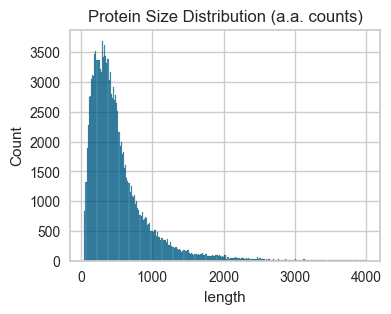

Sequences df dims: (140233, 3)


,uniprot_id,sequence,length
0,A0A0G2K6R9,MMNEDAAQKSDSGEKFNGSSQRRKRPKKSDSNASFLRAARAGNLDK...,3998
1,A0A2R8Q1V0,MGRFTIYRVLKKSGLSGLKVLKPQKCSFQPCSNTLTYTCQDCICYN...,3997
2,Q9Y4D8,MPANHLPIGSTMSTVHLSSDGTYFYWIWSPASLNEKTPKGHSVFMD...,3996
3,A0A5F9ZH30,MTTMLQKSDSNASFLRAARAGNLDKVVEYLKGGIDINTCNQNGLNA...,3995
4,Q80TY5,MLESYVTPILMSYVNRYIKNLKPSDLQLSLWGGDVVLSKLELKLDV...,3993


In [9]:
# Load and parse sequences from CAFA5

sequences = []  # empty list to store parsed sequences

for record in SeqIO.parse(root / "data/cafa5/train_sequences.fasta", "fasta"):
    sequences.append(record)

# Creates sequence df with sequence lengths
# Empty list to store sequences and sequence lengths
seqs_lengths = []

# Iterates over sequences to get the length
for idx, sequence in tqdm(enumerate(sequences), total=len(sequences)):
    # extract terms
    uniprot_id = sequence.id
    seq = "".join(sequence.seq)
    length = len(sequence)

    seqs_lengths.append([uniprot_id, seq, length])

# Creates df with seqs and seqs' lengths and save it
column_names = ["uniprot_id", "sequence", "length"]
sequences_df = pd.DataFrame(data=seqs_lengths, columns=column_names)
sequences_df = sequences_df.sort_values(by="length", ascending=False)
sequences_df.reset_index(drop=True)

# Checking sequence lengths
min_length = 50  # min length threshold
max_length = 4000  # max length threshold

print(
    f"Proteins ({max_length} residues) --> {len(sequences_df[sequences_df['length'] >= max_length])}"
)
print(
    f"Proteins ({min_length} residues) --> {len(sequences_df[sequences_df['length'] <= min_length])}"
)

# Removes large proteins
sequences_df = sequences_df[
    (sequences_df["length"] <= max_length) & (sequences_df["length"] >= min_length)
]
sequences_df.reset_index(drop=True, inplace=True)

# Plots histogram with protein size distribution (removed long sequences)
plt.figure(figsize=(4, 3))

sns.histplot(sequences_df, x="length").set(
    title="Protein Size Distribution (a.a. counts)"
)
plt.show()


print(f"Sequences df dims: {sequences_df.shape}")
sequences_df.head()

In [10]:
# Load protein-GO associations

associations_df = pd.read_csv(root / "data/associations/associations.tsv", sep="\t")

print(f"Protein-GO associations dims: {associations_df.shape}")
associations_df.head()

Protein-GO associations dims: (5363863, 3)


,uniprot_id,go_id,aspect
0,A0A009IHW8,GO:0008152,BPO
1,A0A009IHW8,GO:0034655,BPO
2,A0A009IHW8,GO:0072523,BPO
3,A0A009IHW8,GO:0044270,BPO
4,A0A009IHW8,GO:0006753,BPO


In [11]:
# filter protein-go associations with valid ids

# Remove associations with large proteins
associations_filtered_df = associations_df[
    associations_df["uniprot_id"].isin(sequences_df["uniprot_id"].unique())
]
associations_filtered_df.reset_index(drop=True, inplace=True)

# Save filtered df
file_path = root / "data/associations_yeast.tsv"
associations_filtered_df.to_csv(file_path, sep="\t", index=False)


print(f"Filtered Protein-GO associations dims: {associations_filtered_df.shape}")
print(f"# of unique UniProt IDs: {len(associations_filtered_df['uniprot_id'].unique())}")
associations_filtered_df.head()

Filtered Protein-GO associations dims: (5299803, 3)
# of unique UniProt IDs: 140233


,uniprot_id,go_id,aspect
0,A0A009IHW8,GO:0008152,BPO
1,A0A009IHW8,GO:0034655,BPO
2,A0A009IHW8,GO:0072523,BPO
3,A0A009IHW8,GO:0044270,BPO
4,A0A009IHW8,GO:0006753,BPO


In [12]:
# Obtain intersection of protein ids (PPI vs CAFA5)

# Get unique ids in CAFA5 dataset
# From sequence list to exclude large proteins
cafa_unique_ids = associations_filtered_df["uniprot_id"].unique()

# Determine intersection
intersection_ids, ppi_idx, cafa_idx = np.intersect1d(
    ppi_unique_ids,
    cafa_unique_ids,
    assume_unique=True,
    return_indices=True,
)

print(f"# of unique uniprot ids (CAFA5): {len(cafa_unique_ids)}")
print(f"# of unique uniprot ids (PPI): {len(ppi_unique_ids)}")
print(f"# of intersecting UniProt IDs: {len(intersection_ids)}")

# of unique uniprot ids (CAFA5): 140233
# of unique uniprot ids (PPI): 4476
# of intersecting UniProt IDs: 4468


In [13]:
# Filter out PPI pairs without associaton to GO

# Iterates over unique PPI pairs and check each in intersection ids
ppi_unique_pairs_filtered = [
    (idA, idB)
    for idA, idB in ppi_unique_pairs
    if (idA in intersection_ids) & (idB in intersection_ids)
]

print(f"# of filtered PPI pairs (PPI vs CAFA5): {len(ppi_unique_pairs_filtered)}")

# of filtered PPI pairs (PPI vs CAFA5): 20983


In [14]:
# Remove PPI nodes without associations with GO

# Extract ids in both PPI and CAFA5 datasets (intersect indices)
unique_ids_ppi_associations = ppi_unique_ids[ppi_idx]

# Create boolean mask for elements not selected
mask = np.ones(ppi_unique_ids.shape, dtype=bool)
mask[ppi_idx] = False

# Extract complement
unique_ids_ppi_no_associations = ppi_unique_ids[mask]

# Save UniProt IDS without GO associations
file_path = root / "metadata/Sc_ids_no_associations.txt"
with open(file_path, "w") as f:
    f.write(str(unique_ids_ppi_no_associations))

print(f"Shape of selected uniprot IDs: {unique_ids_ppi_associations.shape}")
print(f"Shape of not-selected uniprot IDs: {unique_ids_ppi_no_associations.shape}")

Shape of selected uniprot IDs: (4468,)
Shape of not-selected uniprot IDs: (8,)


In [15]:
# Construct nx graph

# Create undirected graph instance
yeast_ppi_graph = nx.Graph()

# Add edges
yeast_ppi_graph.add_edges_from(ppi_unique_pairs_filtered)

# Remove self-loops (self-interaction)
yeast_ppi_graph.remove_edges_from(nx.selfloop_edges(yeast_ppi_graph))

print(f"# of nodes: {yeast_ppi_graph.number_of_nodes()}")
print(f"# of edges: {yeast_ppi_graph.number_of_edges()}")

# of nodes: 4468
# of edges: 20983


In [16]:
# Extract Largest Connected Component (LCC)

# Get connected components and lcc
cc = list(nx.connected_components(yeast_ppi_graph))
lcc = max(cc, key=len)

# Extract subgraph with lcc
yeast_ppi_graph_lcc = yeast_ppi_graph.subgraph(lcc).copy()

# Extract nodes and edges for graph dataset
ppi_nodes = yeast_ppi_graph_lcc.nodes()
ppi_edges = list(yeast_ppi_graph_lcc.edges())


# print-out basic graph attributes
print(f"# of nodes: {yeast_ppi_graph.number_of_nodes()}")
print(f"# of edges: {yeast_ppi_graph.number_of_edges()}")
print(f"Is connected?: {nx.is_connected(yeast_ppi_graph)}")
print(f"\n# of connected components: {len(cc)}")
print(f"\n# of nodes (LCC): {len(ppi_nodes)}")
print(f"# of edges (LCC): {len(ppi_edges)}")
print(f"Is connected? (LCC): {nx.is_connected(yeast_ppi_graph_lcc)}")

# of nodes: 4468
# of edges: 20983
Is connected?: False

# of connected components: 19

# of nodes (LCC): 4431
# of edges (LCC): 20964
Is connected? (LCC): True


In [17]:
# Load GO df with definitions

go_df = pd.read_csv(root /"data/go/go-basic-tokenized.csv")
print(go_df.head().to_markdown())

|    | go_id      | name                                                     | aspect             | def                                                                                                                                                                                                                                                                                           |   def_word_count | preprocessed                                                                                                                                                                                      |   preproc_word_count |
|---:|:-----------|:---------------------------------------------------------|:-------------------|:----------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------

#### Degree

Nodes with very high degree centrality (e.g., nodes with more than 250 links as you mentioned) are often hubs that interact with many other proteins. These hubs are crucial but can dominate the signal in a GNN, leading to the mentioned over-smoothing issues. Use different types of GNN layers that are less sensitive to node degree (e.g., GraphSAGE).

In [ ]:
degree_centrality_dict = plot_graph_centrality(
    G=yeast_ppi_graph_lcc,
    centrality_type="degree",
    num_top_nodes=100,
    iterations=1000,
    edge_alpha=0.2,
    figure_size=(16, 16),
    plot_labels=False,
)

# print out top nodes
num_nodes = 20
for key in list(degree_centrality_dict)[:num_nodes]:
    print(f"ID: {key}, centrality: {degree_centrality_dict[key]}")

In [ ]:
# EDA of first 100 nodes

# Obtain annotations of top nodes
ids_to_annotate = list(degree_centrality_dict.keys())[:100]
_, centrality_go_df = annotate_proteins(ids_to_annotate)

# Map GO annotations to definitions
degree_go_df = centrality_go_df.drop(columns=["aspect", "name"]).merge(
    go_df, on="go_id", how="left"
)

print(f"# after NA drop: {centrality_go_df.shape[0]}")

centrality_go_df.dropna(inplace=True)  # drop NAs for TF-IDF and aspect count

print(f"# after NA drop: {centrality_go_df.shape[0]}")

# plot tf-idf
plot_tfidf(degree_go_df["preprocessed"])

# print out aspect counts
print(degree_go_df.value_counts(subset=["aspect"]))

#### Eigenvector Centrality

Eigenvector centrality assigns relative scores to all nodes in the network based on the principle that connections to high-scoring nodes contribute more to the score of the node than equal connections to low-scoring nodes. This can be particularly useful in highlighting proteins that, while not necessarily having a high number of interactions, are significantly influential due to their strategic position within core clusters.

In [ ]:
eigenvector_centrality_dict = plot_graph_centrality(
    G=yeast_ppi_graph_lcc,
    centrality_type="eigenvector",
    num_top_nodes=100,
    iterations=1000,
    edge_alpha=0.2,
    figure_size=(6, 6),
    plot_labels=False,
)

# print out top nodes
num_nodes = 20
for key in list(eigenvector_centrality_dict)[:num_nodes]:
    print(f"ID: {key}, centrality: {eigenvector_centrality_dict[key]}")

In [ ]:
# EDA of first 100 nodes

# Obtain annotations of top nodes
ids_to_annotate = list(eigenvector_centrality_dict.keys())[:100]
_, centrality_go_df = annotate_proteins(ids_to_annotate)

# Map GO annotations to definitions
centrality_go_df = centrality_go_df.drop(columns=["aspect", "name"]).merge(
    go_df, on="go_id", how="left"
)

print(f"# after NA drop: {centrality_go_df.shape[0]}")

centrality_go_df.dropna(inplace=True)  # drop NAs for TF-IDF and aspect count

print(f"# after NA drop: {centrality_go_df.shape[0]}")

# plot tf-idf
plot_tfidf(centrality_go_df["preprocessed"])

# print out aspect counts
print(centrality_go_df.value_counts(subset=["aspect"]))

#### Closeness Centrality

Closeness centrality measures how close a node is to all other nodes in the network (i.e., the average length of the shortest path from the node to all other nodes). This measure helps identify nodes that can quickly interact with the rest of the network, potentially essential for rapid signal transduction. In GNNs, understanding closeness centrality can help in weighting nodes differently based on their ability to influence or be influenced by the network swiftly.

In [ ]:
closeness_centrality_dict = plot_graph_centrality(
    G=yeast_ppi_graph_lcc,
    centrality_type="closeness",
    num_top_nodes=100,
    iterations=1000,
    edge_alpha=0.2,
    figure_size=(6, 6),
    plot_labels=False,
)

# print out top nodes
num_nodes = 20
for key in list(closeness_centrality_dict)[:num_nodes]:
    print(f"ID: {key}, centrality: {closeness_centrality_dict[key]}")

In [ ]:
# EDA of first 100 nodes

# Obtain annotations of top nodes
ids_to_annotate = list(closeness_centrality_dict.keys())[:100]
_, centrality_go_df = annotate_proteins(ids_to_annotate)

# Map GO annotations to definitions
centrality_go_df = centrality_go_df.drop(columns=["aspect", "name"]).merge(
    go_df, on="go_id", how="left"
)

print(f"# after NA drop: {centrality_go_df.shape[0]}")

centrality_go_df.dropna(inplace=True)  # drop NAs for TF-IDF and aspect count

print(f"# after NA drop: {centrality_go_df.shape[0]}")

# plot tf-idf
plot_tfidf(centrality_go_df["preprocessed"])

# print out aspect counts
print(centrality_go_df.value_counts(subset=["aspect"]))

#### Betweenness Centrality

Betweenness centrality measures the number of times a node acts as a bridge along the shortest path between two other nodes. This measure can identify nodes that control the flow of information in the graph, which can be critical in understanding signaling pathways and interaction dynamics in PPI networks. Nodes with high betweenness may be crucial for maintaining the structural integrity of the network or for spreading information. In the context of GNNs, we might consider giving special treatment to these nodes or analyzing their role in learning tasks.

In [ ]:
# Betweenness centrality

betweenness_centrality_dict = plot_graph_centrality(
    G=yeast_ppi_graph_lcc,
    centrality_type="betweenness",
    num_top_nodes=100,
    iterations=1000,
    edge_alpha=0.2,
    figure_size=(6, 6),
)

# print out top nodes
num_nodes = 20
for key in list(betweenness_centrality_dict)[:num_nodes]:
    print(f"ID: {key}, centrality: {betweenness_centrality_dict[key]}")

In [ ]:
# EDA of first 100 nodes

# Obtain annotations of top nodes
ids_to_annotate = list(betweenness_centrality_dict.keys())[:100]
_, centrality_go_df = annotate_proteins(ids_to_annotate)

# Map GO annotations to definitions
centrality_go_df = centrality_go_df.drop(columns=["aspect", "name"]).merge(
    go_df, on="go_id", how="left"
)

print(f"# after NA drop: {centrality_go_df.shape[0]}")

centrality_go_df.dropna(inplace=True)  # drop NAs for TF-IDF and aspect count

print(f"# after NA drop: {centrality_go_df.shape[0]}")

# plot tf-idf
plot_tfidf(centrality_go_df["preprocessed"])

# print out aspect counts
print(centrality_go_df.value_counts(subset=["aspect"]))

#### Clustering Coefficient

The degree to which nodes in a graph tend to cluster together. This metric is particularly useful in networks where the formation of tightly knit groups is a significant characteristic, such as social networks, biological networks, or communication networks.

- Modeling Decisions: Networks with high clustering might suggest the use of models that can capture this local structure effectively, such as those incorporating higher-order neighborhood information.
- Feature Engineering: The clustering coefficient of nodes could be used as a feature in machine learning models, potentially helping the model learn about local node environments.
- Network Sampling: In large graphs, knowing where the high clustering coefficients are might help in sampling subgraphs more effectively for training GNNs.


In [ ]:
# Clustering Coefficient

clustering_dict = plot_centrality_histogram(
    yeast_ppi_graph_lcc,
    "clustering",
    bins=100,
)

In [ ]:
# EDA of first 100 nodes

# Obtain annotations of top nodes
ids_to_annotate = list(clustering_dict.keys())[:100]
_, centrality_go_df = annotate_proteins(ids_to_annotate)

# Map GO annotations to definitions
centrality_go_df = centrality_go_df.drop(columns=["aspect", "name"]).merge(
    go_df, on="go_id", how="left"
)

print(f"# after NA drop: {centrality_go_df.shape[0]}")

centrality_go_df.dropna(inplace=True)  # drop NAs for TF-IDF and aspect count

print(f"# after NA drop: {centrality_go_df.shape[0]}")

# plot tf-idf
plot_tfidf(centrality_go_df["preprocessed"])

# print out aspect counts
print(centrality_go_df.value_counts(subset=["aspect"]))

## Embeddings

October 1, 2022): 7112–27. https://doi.org/10.1109/TPAMI.2021.3095381.

In [18]:
# Load embeddings dict

save_file_path = root / "embeddings/proteins/custom/protein_embeddings_yeast.pkl"
with open(save_file_path, "rb") as file:
    protein_embed_dict = pickle.load(file)

print(f"# of protein embeddings in dict: {len(protein_embed_dict)}")

# of protein embeddings in dict: 4431


In [20]:
# Creates dataframe with GO embeddings

# create dataframe
protein_embeddings_df = (
    pd.DataFrame.from_dict(protein_embed_dict, orient="index")
    .reset_index(drop=False)
    .rename(columns={"index": "uniprot_id"})
)


print(f"Protein embeddings df shape: {protein_embeddings_df.shape}")
print(protein_embeddings_df.head().to_markdown())
protein_embeddings_df

Protein embeddings df shape: (4431, 1025)
|    | uniprot_id   |           0 |          1 |            2 |          3 |          4 |           5 |           6 |           7 |           8 |            9 |          10 |         11 |          12 |         13 |          14 |         15 |         16 |          17 |         18 |         19 |          20 |          21 |          22 |         23 |        24 |          25 |        26 |          27 |        28 |         29 |         30 |          31 |         32 |          33 |          34 |         35 |           36 |          37 |          38 |          39 |          40 |          41 |          42 |          43 |          44 |          45 |          46 |           47 |        48 |           49 |           50 |         51 |         52 |          53 |          54 |           55 |        56 |         57 |         58 |         59 |          60 |          61 |         62 |          63 |          64 |        65 |          66 |           67 |         

,uniprot_id,0,1,2,3,4,5,6,7,8,...,1014,1015,1016,1017,1018,1019,1020,1021,1022,1023
0,P23201,-0.049072,-0.020218,-0.006821,-0.017914,-0.056519,-0.037903,-0.002642,-0.070923,-0.003578,...,0.007053,0.043579,-0.015236,-0.035400,0.020096,0.021362,-0.028732,0.005062,0.026672,0.055115
1,P14020,-0.006874,0.012428,0.020782,0.020569,-0.010017,-0.015625,-0.006535,-0.028809,-0.016037,...,-0.029510,-0.005009,0.021057,-0.005524,-0.036804,-0.016968,-0.043579,-0.014061,0.002449,-0.019302
2,P25659,-0.049866,-0.041046,0.021378,-0.013458,-0.049683,0.013016,-0.009758,0.003281,-0.003429,...,-0.004337,0.064453,-0.008713,0.033234,-0.010719,-0.055389,-0.010689,-0.002371,-0.005306,0.024948
3,P43614,-0.030487,0.009163,0.033844,0.032501,-0.039215,0.010757,0.007336,0.016525,-0.026581,...,0.052734,0.024292,-0.011757,-0.019745,0.008636,0.003666,0.025208,0.001863,0.017166,0.048218
4,Q07987,0.040375,0.029984,-0.000088,-0.007812,-0.021088,-0.005432,0.017151,0.025467,-0.022263,...,0.069824,0.000674,-0.031677,0.038116,-0.030777,-0.037842,-0.007874,0.005676,0.002903,0.065674
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
4426,P53632,0.012634,-0.001407,0.048492,0.000911,-0.047821,-0.003380,0.008102,-0.034302,-0.022034,...,0.002832,0.056030,0.011284,-0.033051,-0.027832,-0.019440,-0.012466,-0.019287,-0.016357,0.007801
4427,Q12287,0.021652,-0.013069,0.006195,-0.017059,0.003294,-0.052185,0.002859,-0.021957,0.004864,...,0.021484,0.055389,0.029449,0.012146,-0.022964,-0.061707,-0.030045,-0.004875,-0.013802,0.014656
4428,P40354,-0.023407,0.008636,0.068726,-0.001020,-0.061615,-0.007458,-0.005119,0.008293,-0.012039,...,0.012375,0.034271,-0.000466,-0.023865,-0.007633,-0.011421,0.000950,-0.001863,0.006229,-0.001131
4429,P21657,-0.040771,0.026230,0.005569,0.008118,-0.050537,-0.036041,-0.022964,-0.021362,0.007980,...,-0.010361,0.066345,-0.007393,-0.016220,-0.018845,-0.019669,-0.013702,0.003736,0.012520,0.023804


In [21]:
# find clusters

# Extract feature matrix
prot_feats = protein_embeddings_df.iloc[:, 1:]

num_of_neighbors = (3, 5, 7)

for n in num_of_neighbors:
    clusterer = hdbscan.HDBSCAN(min_cluster_size=n)
    cluster_labels = clusterer.fit_predict(prot_feats)

    # scoring clustering with silhouette
    scores = silhouette_score(prot_feats, cluster_labels)
    print(
        f"# neighbors = {n}, # clusters = {len(np.unique(cluster_labels))} | Mean Silhouette Score = {scores:.2f}"
    )

# neighbors = 3, # clusters = 3 | Mean Silhouette Score = 0.19
# neighbors = 5, # clusters = 3 | Mean Silhouette Score = 0.21
# neighbors = 7, # clusters = 4 | Mean Silhouette Score = 0.08


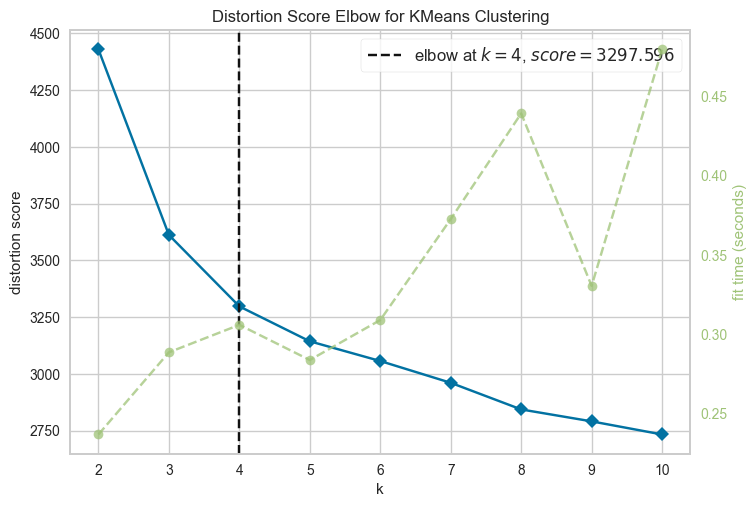

In [22]:
# clustering with elbow method to determine best num of clusters

# yellowbrick KMeans with elbow and viz
model = KElbowVisualizer(KMeans(n_init="auto"), k=10)

model.fit(prot_feats)
model.show()
plt.show()

In [68]:
# sklearn kmeans

num_clusters = 5  # estimated number of clusters with 2 or 3 neighbors

kmeans = KMeans(n_clusters=num_clusters, n_init="auto", random_state=42).fit(prot_feats)

# add to tsne results
protein_embeddings_df["kmeans_cluster"] = kmeans.labels_

# group mol_id by cluster
cluster_gols = (
    protein_embeddings_df.groupby("kmeans_cluster")["uniprot_id"]
    .agg(lambda x: list(x))
    .sort_values()
)

# create df with clusters and number of items per cluster
cluster_gols_counts = pd.DataFrame(cluster_gols)
cluster_gols_counts.insert(0, "n_items", [len(x) for x in cluster_gols])
cluster_gols_counts.sort_values(by="n_items", ascending=False, inplace=True)
cluster_gols_counts.reset_index(drop=False, inplace=True)


print(f"Protein embeddings shape: {protein_embeddings_df.shape}")

cluster_gols_counts

Protein embeddings shape: (4431, 1026)


,kmeans_cluster,n_items,uniprot_id
0,3,1151,"[P25659, Q07987, Q12239, P39543, P25339, P5479..."
1,2,1071,"[P39704, P53378, P38860, Q03630, P43553, P1517..."
2,1,1007,"[P23201, P43614, P21705, P53248, Q04233, Q9917..."
3,0,779,"[P14020, P47001, P22141, P22214, P26637, P2214..."
4,4,423,"[P00830, P04173, Q02908, P25296, P21801, P3869..."


In [26]:
# UMAP with 3 components for 3D visualization (with dimensionality reduction)

# Reduce dimensionality to be manageable
pca = PCA(n_components=8, random_state=42)

prot_feats_pca = pca.fit_transform(prot_feats)

# create a dictionary to store the outputs
umap_dict = {}

# parameters
n_neighbors_list = [3, 5, 10, 15, 20, 30]
min_dist_list = [0.0, 0.2, 0.5, 0.8, 0.99]
metrics = ["cosine", "euclidean", "hamming", "manhattan", "braycurtis"]
n_epochs = [100]
learning_rate = 1

# for progress tracking
total_iterations = (
    len(n_neighbors_list) * len(min_dist_list) * len(metrics) * len(n_epochs)
)

parameter_combinations = product(n_neighbors_list, min_dist_list, metrics, n_epochs)


for n_neighbors, min_dist, metric, epoch in tqdm(
    parameter_combinations, total=total_iterations, desc="UMAP Parameter Search"
):

    reducer = umap.UMAP(
        n_components=3,
        n_neighbors=n_neighbors,
        metric=metric,
        n_epochs=epoch,
        learning_rate=learning_rate,
        min_dist=min_dist,
        verbose=False,
        random_state=42,
    )
    results = reducer.fit_transform(prot_feats_pca)

    # store results
    umap_dict.update({f"{n_neighbors}_{min_dist}_{metric}_{epoch}": results})


# create dataframe with results for ploting
# initialize df to concatenate
df_umap = pd.DataFrame()

# iterates of tsne results and add the columns
for key, value in umap_dict.items():
    df_umap = pd.concat([df_umap, pd.DataFrame(value)], axis=1)

# create column names
coordinates = ["x", "y", "z"]
columns_names = [
    f"{coordinate}_{str(n_neighbors)}_{str(min_dist)}_{metric}_{str(epoch)}"
    for n_neighbors in n_neighbors_list
    for min_dist in min_dist_list
    for metric in metrics
    for epoch in n_epochs
    for coordinate in coordinates
]

df_umap.columns = columns_names
df_umap = pd.concat(
    [
        protein_embeddings_df[["uniprot_id", "kmeans_cluster"]].reset_index(
            drop=True
        ),
        df_umap,
    ],
    axis=1,
)

# save grid search
df_umap.to_csv(
    root / "clustering/protein//umap_grid_pca.csv",
    index=False,
)

print(df_umap.shape)
df_umap.head()

UMAP Parameter Search:   0%|          | 0/150 [00:00<?, ?it/s]

(4431, 452)


,uniprot_id,kmeans_cluster,x_3_0.0_cosine_100,y_3_0.0_cosine_100,z_3_0.0_cosine_100,x_3_0.0_euclidean_100,y_3_0.0_euclidean_100,z_3_0.0_euclidean_100,x_3_0.0_hamming_100,y_3_0.0_hamming_100,...,z_30_0.99_euclidean_100,x_30_0.99_hamming_100,y_30_0.99_hamming_100,z_30_0.99_hamming_100,x_30_0.99_manhattan_100,y_30_0.99_manhattan_100,z_30_0.99_manhattan_100,x_30_0.99_braycurtis_100,y_30_0.99_braycurtis_100,z_30_0.99_braycurtis_100
0,P23201,1,7.851668,2.987539,6.878771,2.781461,9.766701,7.956775,5.341117,-0.602752,...,7.058816,0.687079,4.773234,2.112173,0.416971,4.404602,12.115014,0.717826,6.727063,-1.736534
1,P14020,0,11.307659,5.095296,7.267694,-1.307741,5.554878,5.168308,2.655882,3.171821,...,8.659011,8.126828,2.639455,7.913054,8.589439,10.257970,6.692634,8.690560,0.340567,3.047662
2,P25659,1,12.628192,4.940416,4.098536,5.653568,10.461716,9.224721,8.961827,6.525719,...,4.359248,-0.345510,2.987639,5.072882,-0.085828,6.836797,10.183842,1.513400,4.285054,0.123287
3,P43614,1,12.438994,1.488217,3.516465,6.329790,5.623900,7.937378,6.916577,8.977072,...,2.937851,-1.210988,4.424607,6.959357,-2.408715,4.984007,7.127244,-2.328431,4.439644,2.897696
4,Q07987,1,12.090990,4.581802,0.568764,5.644079,10.614655,9.353515,5.422279,0.288101,...,3.380098,1.118920,4.268011,6.025588,0.623681,6.690710,8.356773,1.464452,4.037965,1.973679


In [27]:
# load umap grid search

df_umap = pd.read_csv(root / "clustering/protein/umap_grid_pca.csv")
df_umap.shape

(4431, 452)

In [49]:
# interactive plot

# plot
n_neighbors = 3
min_dist = 0.99
metric = "euclidean"
epochs = 100
width = 800
height = 600
size = 2
opacity = 0.8


fig = px.scatter_3d(
    df_umap,
    x=f"x_{str(n_neighbors)}_{str(min_dist)}_{metric}_{epochs}",
    y=f"y_{str(n_neighbors)}_{str(min_dist)}_{metric}_{epochs}",
    z=f"z_{str(n_neighbors)}_{str(min_dist)}_{metric}_{epochs}",
    color=df_umap["kmeans_cluster"],
    labels={"color": "kmeans_cluster"},
    hover_data=["uniprot_id"],
)
fig.update_traces(marker=dict(size=size), opacity=opacity)
fig.update_layout(width=width, height=height)
fig.show()

In [57]:
# UMAP single shot

# parameters
n_neighbors = 20
min_dist = 0.99
metric = "cosine"
epoch = 5000
learning_rate = 1
width = 800
height = 600
size = 2
opacity = 0.7

# fit data
reducer = umap.UMAP(
    n_components=3,
    n_neighbors=n_neighbors,
    metric=metric,
    n_epochs=epoch,
    learning_rate=learning_rate,
    min_dist=min_dist,
    verbose=False,
    random_state=42,
)
results = reducer.fit_transform(prot_feats)

# add to df
df_umap_sample = pd.DataFrame(results, columns=["x", "y", "z"])

# add columns from go samples
df_umap_sample.insert(0, "uniprot_id", np.array(protein_embeddings_df["uniprot_id"]))
df_umap_sample.insert(3, "kmeans_cluster", np.array(protein_embeddings_df["kmeans_cluster"]))

# Save to CSV
df_umap_sample.to_csv(root / "clustering/protein/umap_single_pca.csv", index=False)

# interactive plot
width = 800
height = 600


# kmeans cluster labels
fig = px.scatter_3d(
    df_umap_sample,
    x="x",
    y="y",
    z="z",
    color="kmeans_cluster",
    labels={"color": "cluster"},
    hover_data=["uniprot_id"],
)

fig.update_traces(marker=dict(size=size), opacity=opacity)
fig.update_layout(width=width, height=height)

fig.show()

### Spectral Embedding (Spectral embedding for non-linear dimensionality reduction using Laplacian Eigenmaps)

In [72]:
# spectral embedding

# create a dictionary to store the outputs
se_dict = {}

n_neighbors = [3, 5, 10, 20, 30, 50, 100]

for n_neighbor in tqdm(
    n_neighbors, total=len(n_neighbors), desc="Searching n_neighbors..."
):

    se = SpectralEmbedding(
        n_components=3,
        n_neighbors=n_neighbor,
        affinity="rbf",
        random_state=42,
        n_jobs=-1,
    )
    results = se.fit_transform(prot_feats_pca)

    se_dict.update({n_neighbor: results})


# create dataframe with results for ploting
# initialize df to concatenate
df_se = pd.DataFrame()

# iterates of tsne results and add the columns
for key, value in se_dict.items():
    df_se = pd.concat([df_se, pd.DataFrame(value)], axis=1)

# create column names
coordinates = ["x", "y", "z"]
columns_names = [
    f"{item2}_{str(item1)}" for item1 in n_neighbors for item2 in coordinates
]

df_se.columns = columns_names

# add data to go_df_sample dataframe
df_se = pd.concat(
    [
        protein_embeddings_df[["uniprot_id", "kmeans_cluster"]].reset_index(
            drop=True
        ),
        df_se,
    ],
    axis=1,
)

# save grid search
df_se.to_csv(root / "clustering/protein/se_grid.csv", index=False)

print(df_se.shape)
df_se.head()

Searching n_neighbors...:   0%|          | 0/7 [00:00<?, ?it/s]

(4431, 23)


,uniprot_id,kmeans_cluster,x_3,y_3,z_3,x_5,y_5,z_5,x_10,y_10,...,z_20,x_30,y_30,z_30,x_50,y_50,z_50,x_100,y_100,z_100
0,P23201,1,-0.000235,0.000278,0.000406,-0.000235,0.000278,0.000406,-0.000235,0.000278,...,0.000406,-0.000235,0.000278,0.000406,-0.000235,0.000278,0.000406,-0.000235,0.000278,0.000406
1,P14020,0,0.000297,-0.000055,-0.000331,0.000297,-0.000055,-0.000331,0.000297,-0.000055,...,-0.000331,0.000297,-0.000055,-0.000331,0.000297,-0.000055,-0.000331,0.000297,-0.000055,-0.000331
2,P25659,3,-0.000213,-0.000016,0.000297,-0.000213,-0.000016,0.000297,-0.000213,-0.000016,...,0.000297,-0.000213,-0.000016,0.000297,-0.000213,-0.000016,0.000297,-0.000213,-0.000016,0.000297
3,P43614,1,-0.000292,0.000197,-0.000514,-0.000292,0.000197,-0.000514,-0.000292,0.000197,...,-0.000514,-0.000292,0.000197,-0.000514,-0.000292,0.000197,-0.000514,-0.000292,0.000197,-0.000514
4,Q07987,3,-0.000155,-0.000054,0.000200,-0.000155,-0.000054,0.000200,-0.000155,-0.000054,...,0.000200,-0.000155,-0.000054,0.000200,-0.000155,-0.000054,0.000200,-0.000155,-0.000054,0.000200


In [73]:
# load tsne grid search

df_se = pd.read_csv(root / "clustering/protein/se_grid.csv")
df_se.shape

(4431, 23)

In [74]:
# interactive plot

# plot
p = "50"  # n_neighbors

width = 800
height = 600
size = 2
opacity = 0.7

# label: cluster
fig = px.scatter_3d(
    df_se,
    x=f"x_{p}",
    y=f"y_{p}",
    z=f"z_{p}",
    color=df_se["kmeans_cluster"],
    labels={"color": "cluster"},
    hover_data=["uniprot_id"],
)
fig.update_traces(marker=dict(size=size), opacity=opacity)
fig.update_layout(width=width, height=height)
fig.show()